# Sesgo inflacionario: optimizar no basta sin expectativas consistentes

## Resumen
Ancla sintética: compromisoL0,75, discreciónL1,25. Una política ingenua pareceL0,5, pero supone expectativas0 y genera inflación media0,5: no es un equilibrio de expectativas racionales. 54casos con dos estados equiprobables exactos; sin Monte Carlo ni datos reales. S2 local.

## Tres ideas y selección
Se compararon HAC para IV, extensión dinámica de bienes públicos e inconsistencia temporal monetaria. Se eligió la tercera para rotar de modelos recientes y auditar factibilidad de expectativas antes de ordenar objetivos. Teoría clásica; contribución incremental al repositorio, no prioridad científica.

## Modelo y secuencia

$y=\alpha(\pi-\pi^e)+\epsilon$, pérdida $L=\frac12[\pi^2+\lambda(y-k)^2]$. El privado fija $\pi^e$ antes del shock; el banco observa ε y elige π. Bajo discreción el privado anticipa esa mejor respuesta. Bajo compromiso se asume capacidad **costless y creíble** de fijar una regla contingente antes de expectativas; no se implementa un mecanismo institucional que la garantice.

Shock ε∈{−σ,+σ}, probabilidad0,5. Cuando σ0 son dos registros idénticos con peso0,5, no dos observaciones independientes. Variables normalizadas, no tasas calibradas o previsiones macro reales.

In [1]:
import json,csv
from pathlib import Path
import numpy as np
from IPython.display import display,Image
from src.monetary import policies,loss,best_response,oracle
root=Path.cwd()
r=json.loads((root/"results/summary.json").read_text())
print(json.dumps(r["config"],indent=2))

{
  "seed": 20261029,
  "alpha_values": [
    0.5,
    1,
    1.5
  ],
  "weight_values": [
    0.5,
    1,
    2
  ],
  "target_values": [
    0,
    0.5,
    1
  ],
  "shock_scales": [
    0,
    1
  ],
  "anchor": {
    "alpha": 1,
    "weight": 1,
    "target": 1,
    "shock_scale": 1
  },
  "hypothesis": "On54 exact two-state cases: RE residual commitment/discretion<=1e-12; loss gap=0.5*(weight*alpha*target)^2; scalar best-response oracle discrepancy<=1e-6. Anchor naive loss appears lower but RE residual>0, so reject as equilibrium comparison."
}


## Derivación y expectativas racionales

Mejor respuesta condicional: $\pi^{BR}=\lambda\alpha(\alpha\pi^e+k-\epsilon)/(1+\lambda\alpha^2)$. Bajo RE $\pi^e=E\pi=\lambda\alpha k=b$. Por tanto $\pi_D=b-\lambda\alpha\epsilon/(1+\lambda\alpha^2)$.

Compromiso óptimo dentro de reglas afines: $\pi_C=-\lambda\alpha\epsilon/(1+\lambda\alpha^2)$ y esperanza0. Ambas generan $y=\epsilon/(1+\lambda\alpha^2)$; la diferencia exacta de pérdida esperada es $\frac12b^2$. Bajo compromiso se impide reoptimizar ex post: no se verifica la misma mejor respuesta que discreción. La ventaja depende de esa capacidad asumida.

In [2]:
for shock in [-1,1]:
 for name,(pi,e) in policies(shock,1,1,1).items():
  print("Shock",shock,name,"π",pi,"πe",e,"y",pi-e+shock,"L",loss(pi,e,shock,1,1,1))
 print("Oráculo BR discreción",oracle(1,shock,1,1,1))

Shock -1 commitment π 0.5 πe 0.0 y -0.5 L 1.25
Shock -1 discretion π 1.5 πe 1 y -0.5 L 2.25
Shock -1 naive_fixed_expectations π 1.0 πe 0.0 y 0.0 L 1.0
Oráculo BR discreción 1.4999999999597544
Shock 1 commitment π -0.5 πe 0.0 y 0.5 L 0.25
Shock 1 discretion π 0.5 πe 1 y 0.5 L 0.25
Shock 1 naive_fixed_expectations π 0.0 πe 0.0 y 1.0 L 0.0
Oráculo BR discreción 0.5000000049247174


## Datos, baseline y control de admisibilidad
54escenarios de parámetros,3regímenes y2estados producen324registros. Discreción es baselineREfactible. La política ingenua congelaπe0 y usaBR: no debe contarse como régimen factible cuandoEπ≠πe. El oráculo escalar verifica la BRcondicional, no prueba compromiso institucional o causalidad.

In [3]:
rows=list(csv.DictReader((root/"results/cases.csv").open()))
assert len(rows)==54
print("Ancla",r["anchor"])
print("Error identidad de pérdida",r["max_loss_gap_identity_error"])
print("Error máximo BR versus oráculo",r["max_best_response_oracle_error"])
assert r["max_loss_gap_identity_error"]<1e-10
assert r["max_best_response_oracle_error"]<1e-6
for row in rows:
 assert float(row["commitment_re_residual"])<1e-12
 assert float(row["discretion_re_residual"])<1e-12

Ancla {'alpha': 1, 'weight': 1, 'target': 1, 'shock_scale': 1, 'commitment_loss': 0.75, 'discretion_loss': 1.25, 'naive_loss_inconsistent': 0.5, 'commitment_re_residual': 0.0, 'discretion_re_residual': 0.0, 'naive_re_residual': 0.5, 'commitment_mean_output': 0.0, 'discretion_mean_output': 0.0, 'naive_mean_output': 0.5, 'loss_gap_identity_error': 0.0, 'max_best_response_oracle_error': 4.92471741164735e-09}
Error identidad de pérdida 4.440892098500626e-16
Error máximo BR versus oráculo 1.4187990338143663e-08


## Falsación: menor pérdida aparente con equilibrio incumplido
Ancla: naiveL0,5 es menor que compromiso0,75, pero su inflación media0,5 contradiceexpectativa0. Su ganancia media de producto0,5 es sorpresa no anticipada, no un efecto sistemáticoRE. En los dos regímenes consistentes producto medio0. No recomendar una política por su objetivo si incumple restricciones.

In [4]:
a=r["anchor"]
assert a["naive_loss_inconsistent"]<a["commitment_loss"]
assert a["naive_re_residual"]>.4
assert abs(a["commitment_mean_output"])<1e-12
assert abs(a["discretion_mean_output"])<1e-12
print("Naive rechazada como equilibrio; no se cuenta su pérdida como mejora factible.")

Naive rechazada como equilibrio; no se cuenta su pérdida como mejora factible.


## Sensibilidad y control negativo
Cuando k0 desaparece la razón de sesgo: compromiso y discreción coinciden. Las diferencias aquí son exactas bajo el modelo, no errores estadísticos o evidencia de dominancia de reglas rígidas en modelos más amplios.

Control k0 confirmado.


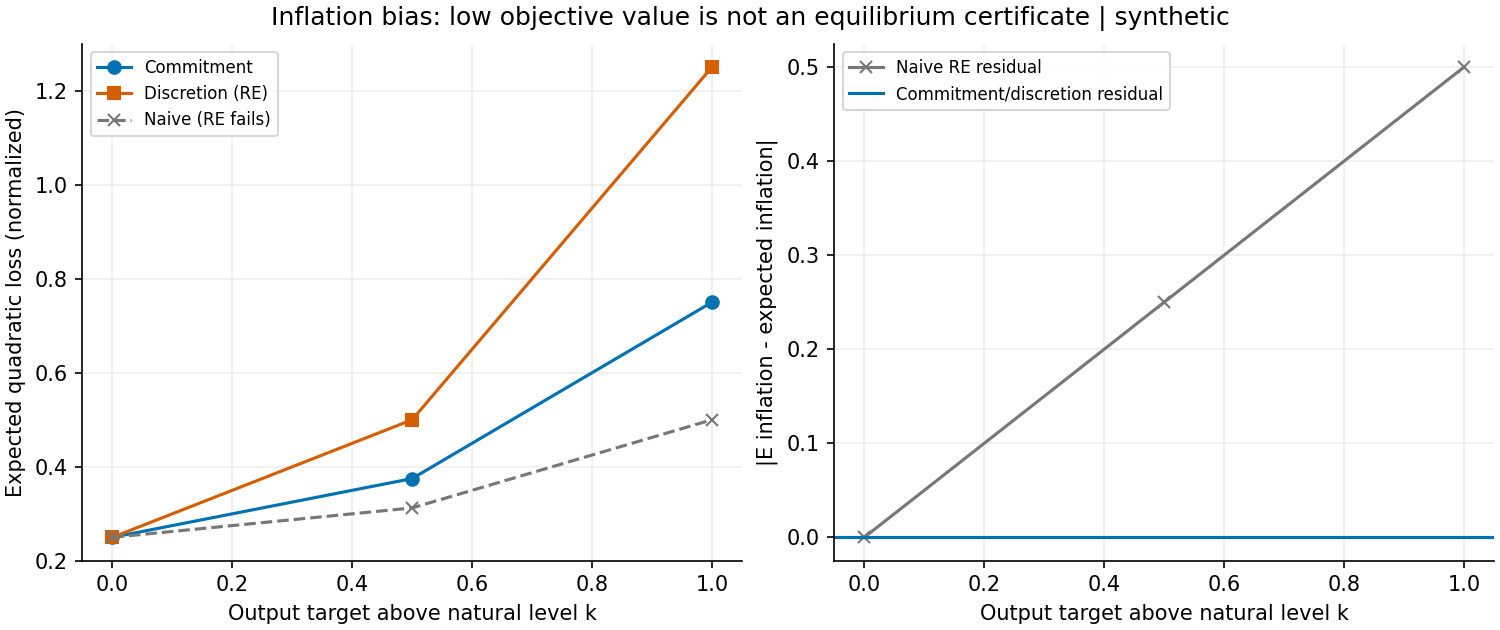

In [5]:
display(Image(filename=str(root/"results/comparison.png")))
for shock in [-1,1]:
 p=policies(shock,1,1,0)
 assert p["commitment"]==p["discretion"]
print("Control k0 confirmado.")

## Coste, trazabilidad y límites
Evaluación de54casos y oráculos escalares medida en tiempo/picoPython, noRSS ni latencia operacional. Sin benchmark de alta dimensión. No agentes heterogéneos, tipo de cambio, dinero, tasa de interés, credibilidad endógena, reputación repetida o estimación de parámetros.

In [6]:
print("Versiones",r["versions"])
print("Segundos instrumentados",r["seconds"],"PicoPython",r["python_peak_bytes"])
print("SHA256 datos",r["data_sha256"])
print("SHA256 núcleo",r["source_sha256"])

Versiones {'python': '3.12.14', 'numpy': '2.3.5', 'scipy': '1.17.0', 'matplotlib': '3.10.8'}
Segundos instrumentados 0.20681969999998273 PicoPython 235526
SHA256 datos fa0ad551a68ad9a3d0064770b8e4bd78ec09182bf3c59911be5547e3cfddf875
SHA256 núcleo 9d40bd8060f0d97f6dc49cdc23e3c29eef32455d1f548d54e6bd74c4e7bfd971


## Preguntas y siguientes pasos
¿Quién garantiza la regla comprometida? ¿Cómo cambian resultados si k depende de distorsiones o expectativas se aprenden? ¿Qué datos identifican α? No se responde con una recomendación para un banco real. Cinco referencias verificadas y un informe14p delimitan alcance.

Ejecución secuencial IPython limpio en proceso sin kernel/socket; errores abortan, outputs persisten; figura inspeccionada sin probar todos los frontends.